<a href="https://colab.research.google.com/github/nicolasrporto/R-Applications/blob/main/Atividade10_An%C3%A1lise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
install.packages('caret')
library(caret)
install.packages('C50', repos='cran.us.r-project.org')
install.packages("randomForest", dependencies = T)
library(C50)
library(randomForest)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘listenv’, ‘parallelly’, ‘future’, ‘globals’, ‘shape’, ‘future.apply’, ‘numDeriv’, ‘progressr’, ‘SQUAREM’, ‘diagram’, ‘lava’, ‘prodlim’, ‘proxy’, ‘iterators’, ‘clock’, ‘gower’, ‘hardhat’, ‘ipred’, ‘sparsevctrs’, ‘timeDate’, ‘e1071’, ‘foreach’, ‘ModelMetrics’, ‘plyr’, ‘pROC’, ‘recipes’, ‘reshape2’




In [ ]:


set.seed(11322768)


dados = as.data.frame(read.table('splus-mag-z.dat', sep = "", header=TRUE))
head(dados)

In [ ]:
coruJAVA_petro = dados$uJAVA_petro - dados$r_petro
corF378_petro = dados$F378_petro - dados$r_petro
corF395_petro = dados$F395_petro - dados$r_petro
corF410_petro = dados$F410_petro - dados$r_petro
corF430_petro = dados$F430_petro - dados$r_petro
corg_petro = dados$g_petro - dados$r_petro
corF515_petro = dados$F515_petro - dados$r_petro
corF660_petro = dados$F660_petro - dados$r_petro
cori_petro = dados$i_petro - dados$r_petro
corF861_petro = dados$F861_petro - dados$r_petro
corz_petro = dados$z_petro - dados$r_petro
corz_SDSS = dados$z_SDSS - dados$r_petro

cores <- data.frame(coluna1 = coruJAVA_petro, coluna2 = corF378_petro, coluna3 = corF395_petro, coluna4=corF410_petro, coluna5=corF430_petro, coluna6=corg_petro, coluna7=corF515_petro, coluna8=corF660_petro, coluna9=cori_petro, coluna10 = corF861_petro, coluna11= corz_petro, coluna12 = corz_SDSS)

In [ ]:
nsample = 10000

# magnitudes
mags = dados[1:nsample,1:11]

# redshift
zspec = dados[1:nsample,12]

summary(mags)


#subtraindo a média e dividir pelo desvio padrão:
magnorm <- as.data.frame(scale(mags, center = TRUE, scale = TRUE))

summary(magnorm)

In [ ]:

numlinhastreinamento =  createDataPartition(zspec, p=0.8, list=FALSE)

# conjunto de treinamento:
xtrain=magnorm[numlinhastreinamento,]
ytrain=zspec[numlinhastreinamento]

# conjunto de teste
xtest=magnorm[-numlinhastreinamento,]
ytest=zspec[-numlinhastreinamento]

t0 = Sys.time()

modelLookup('rf')

model_rf<-train(xtrain,ytrain,method= "rf")

Sys.time() - t0

print(model_rf)

,model,parameter,label,forReg,forClass,probModel
,<chr>,<chr>,<chr>,<lgl>,<lgl>,<lgl>
1,rf,mtry,#Randomly Selected Predictors,TRUE,TRUE,TRUE


Time difference of 1.335204 hours

Random Forest 

8002 samples
  11 predictor

No pre-processing
Resampling: Bootstrapped (25 reps) 
Summary of sample sizes: 8002, 8002, 8002, 8002, 8002, 8002, ... 
Resampling results across tuning parameters:

  mtry  RMSE       Rsquared   MAE       
   2    0.1130396  0.9914841  0.06360410
   6    0.1013906  0.9931896  0.06199802
  11    0.1035373  0.9928964  0.06369019

RMSE was used to select the optimal model using the smallest value.
The final value used for the model was mtry = 6.


In [ ]:
# predição com o conjunto de teste
pred_rf = predict(model_rf, xtest)

relz = (ytest - pred_rf)
#0.7413 está correto para a relação 80-20?
sig_G_rf = 0.7413*(quantile(relz,0.8,names = FALSE) - quantile(relz,0.2,names = FALSE))
sig_G_rf

my_data = as.data.frame(cbind(observed = ytest,predicted = pred_rf))
head(my_data)

[1] 0.07544096

,observed,predicted
,<dbl>,<dbl>
4,17.34,17.35521
5,15.38,15.42370
8,18.06,18.09546
10,17.36,17.38560
13,16.54,16.65264
14,17.84,17.78523


`geom_smooth()` using formula = 'y ~ x'


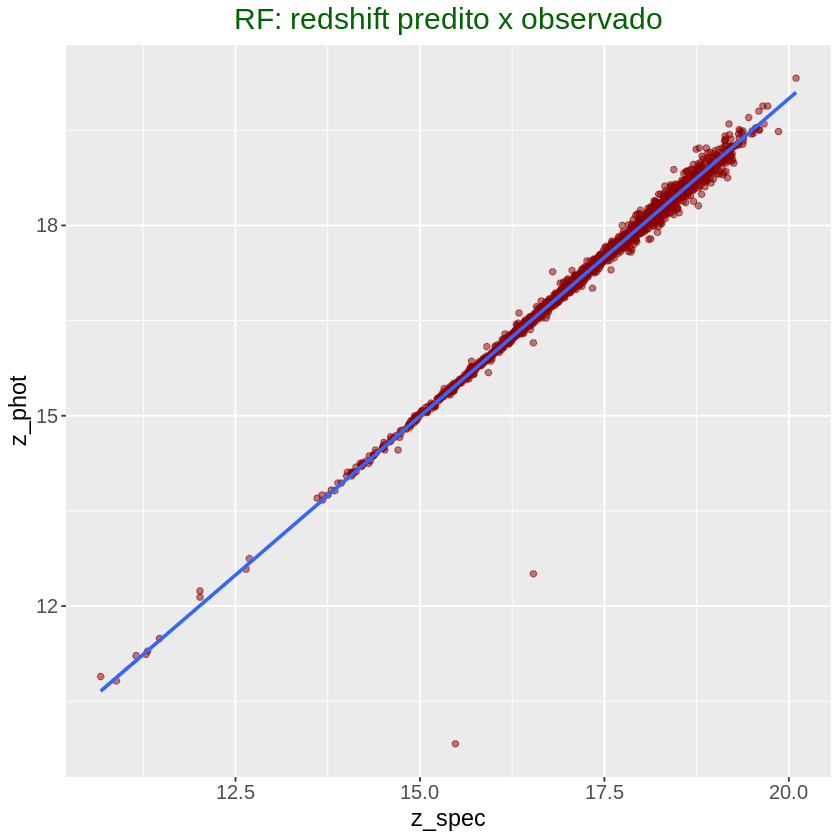

In [ ]:
#visualização

ggplot(my_data,aes(predicted, observed)) +
  geom_point(color = "darkred", alpha = 0.5) +
  geom_smooth(method=lm)+
  ggtitle("RF: redshift predito x observado") +
  xlab("z_spec") +
  ylab("z_phot") +
  theme(plot.title = element_text(color="darkgreen",size=18,hjust = 0.5),
        axis.text.y = element_text(size=12),
        axis.text.x = element_text(size=12,hjust=.5),
        axis.title.x = element_text(size=14),
        axis.title.y = element_text(size=14))

In [ ]:
#Questão2

tabela = as.data.frame(read.table(file="dadosparaestrelagalaxia.dat", header=TRUE))
dim(tabela)

length(tabela$classe[tabela$classe == 0])
length(tabela$classe[tabela$classe == 1])

[1] 10000    13

[1] 5000

[1] 5000

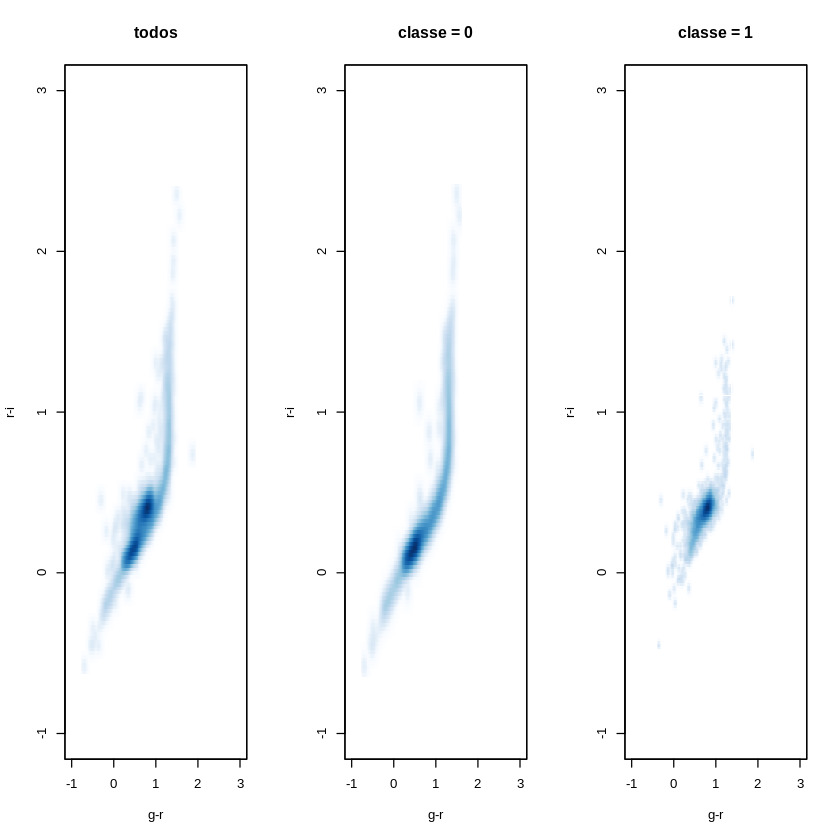

In [ ]:
par(mfrow = c(1,3))
ca = tabela$g_petro-tabela$r_petro
cb = tabela$r_petro-tabela$i_petro
smoothScatter(ca,cb,nrpoints=0,add=FALSE,xlab="g-r",ylab="r-i",xlim=c(-1,3),ylim=c(-1,3),main='todos')
ca = tabela$g_petro[tabela$classe == 0]-tabela$r_petro[tabela$classe == 0]
cb = tabela$r_petro[tabela$classe == 0]-tabela$i_petro[tabela$classe == 0]
smoothScatter(ca,cb,nrpoints=0,add=FALSE,xlab="g-r",ylab="r-i",xlim=c(-1,3),ylim=c(-1,3),main='classe = 0')
ca = tabela$g_petro[tabela$classe == 1]-tabela$r_petro[tabela$classe == 1]
cb = tabela$r_petro[tabela$classe == 1]-tabela$i_petro[tabela$classe == 1]
smoothScatter(ca,cb,nrpoints=0,add=FALSE,xlab="g-r",ylab="r-i",xlim=c(-1,3),ylim=c(-1,3),main='classe = 1')

In [ ]:
# definindo os features
mag = tabela[,1:12]

# pré-processamento: normalização das magnitudes entre 0 e 1
maxs <- apply(mag, 2, max)
mins <- apply(mag, 2, min)
normalizacao <- as.data.frame(scale(mag, center = mins, scale = maxs - mins))

# conjuntos de treinamento (80%) e teste (20%):

ntreino = round(0.80*nrow(tabela))
nteste = nrow(tabela)-ntreino
c(ntreino,nteste)

[1] 8000 2000

In [ ]:
set.seed(11322768)
indice =  createDataPartition(tabela$classe, p=0.8, list=FALSE)
xtrain = normalizacao[indice,]

# 13 ou 12?

ytrain = as.factor(tabela[indice,13])

xtest = normalizacao[-indice,]
ytest = as.factor(tabela[-indice,13])



In [ ]:
t0 = Sys.time()
model_knn <- train(xtrain,ytrain,method='knn',
                      tuneLength = 10,
                      trControl = trainControl(method = "cv"))
Sys.time()-t0

model_knn

pred = predict(model_knn, xtest)
head(pred)
postResample(pred = pred ,obs= ytest)

#comparar resultado de acurácia com a acurácia de 0.9724 para SVM
#Vemos que a acurácia do KNN é um pouco maior do que a obtida no HTML (SVM)


Time difference of 12.63458 secs

k-Nearest Neighbors 

8000 samples
  12 predictor
   2 classes: '0', '1' 

No pre-processing
Resampling: Cross-Validated (10 fold) 
Summary of sample sizes: 7200, 7200, 7200, 7200, 7200, 7200, ... 
Resampling results across tuning parameters:

  k   Accuracy  Kappa  
   5  0.961250  0.92250
   7  0.960125  0.92025
   9  0.959750  0.91950
  11  0.958625  0.91725
  13  0.957875  0.91575
  15  0.955750  0.91150
  17  0.953500  0.90700
  19  0.952375  0.90475
  21  0.951125  0.90225
  23  0.949250  0.89850

Accuracy was used to select the optimal model using the largest value.
The final value used for the model was k = 5.

[1] 0 1 0 1 1 0
Levels: 0 1

Accuracy    Kappa 
   0.959    0.918